# GIE Experiments and Quantum Simulation

This notebook presents a tutorial on the digital quantum simulation of gravitationally-induced entanglement (GIE) experiments using Trotterized Hamiltonian evolution. It establishes the theoretical and computational bridge across:

1. **Bose et al. GIE Proposal:** The physical concept of gravity-mediated entanglement between massive spatial superpositions.
2. **Sabín's 6-Qubit Digitization:** Truncating continuous-variable bosonic interaction modes into a 6-qubit register mapping.
3. **Exact 6-Qubit Evolution:** Computing exact statevector dynamics under $U_\varepsilon = e^{-i\varepsilon \widetilde{H}}$.
4. **Entanglement Quantification:** Measuring concurrence and evaluating a logical correlation witness tailored to the encoded subspace.
5. **IBM Circuit Synthesis:** Decomposing multi-qubit Pauli rotations into hardware-compatible gate operations.

> **Scope Note:** This notebook focuses on real-time entanglement dynamics and concludes prior to ground-state optimization via the Variational Quantum Eigensolver (VQE). VQE addresses a static ground-state optimization problem and should not be confused with real-time entanglement generation.

#### Primary Sources:
1. S. Bose et al., *A Spin Entanglement Witness for Quantum Gravity*, Phys. Rev. Lett. **119**, 240401 (2017) ([arXiv:1707.06050](https://arxiv.org/abs/1707.06050)).
2. C. Marletto and V. Vedral, *Gravitationally Induced Entanglement between Two Massive Particles is Sufficient Evidence of Quantum Effects in Gravity*, Phys. Rev. Lett. **119**, 240402 (2017) ([arXiv:1707.06036](https://arxiv.org/abs/1707.06036)).
3. C. Sabín, *Digital quantum simulation of quantum gravitational entanglement with IBM quantum computers*, EPJ Quantum Technol. **10**, 11 (2023) ([arXiv:2302.04006](https://arxiv.org/abs/2302.04006)).

## 1. Introduction & Theoretical Foundations

**Quantum Gravity Frameworks**

Quantum gravity—the unification of quantum mechanics and general relativity—remains an open problem. Two main approaches exist:

1. Quantization of Gravity: Treats quantum theory as fundamental and quantizes the gravitational field, leading to frameworks such as string theory and loop quantum gravity.

2. Gravitization of Quantum Mechanics: Reverses the priority, modifying quantum mechanics to accommodate a classical spacetime (e.g., semiclassical gravity and Penrose's gravitationally induced collapse).

The [Bose et al.](https://arxiv.org/abs/1707.06050) experiment targets a precise empirical question: Can the gravitational field act as a quantum mediator? Detecting entanglement between two masses interacting solely via gravity provides direct evidence for the quantum nature of the gravitational field without assuming a specific quantum gravity model.

**Entanglement Witness**

In the Bose et al. protocol, entanglement generated via mutual gravitational interaction serves as the key physical witness. The experimentally accessible witness quantity is:
$$
    \mathcal{W}_{\text{Bose}} = \left\vert{} \left\langle \sigma_x^{(1)} \otimes \sigma_z^{(2)} \right\rangle - \left\langle \sigma_y^{(1)} \otimes \sigma_z^{(2)} \right\rangle \right\vert{}
$$
A measured value of $\mathcal{W}_{\text{Bose}} > 1$ constitutes a sufficient criterion for gravitationally induced entanglement.

**Physics of Entanglement**

An $n$-particle quantum state is entangled if it cannot be written as a separable product state:
$$
    \vert{}\Psi_{\text{sep}}\rangle \neq \vert{}\psi_1\rangle \otimes \vert{}\psi_2\rangle \otimes \dots \otimes \vert{}\psi_n\rangle
$$
For an entangled two-spin system, measuring the first particle instantly restricts the outcome of the second regardless of spatial separation. As established by Bell's theorem, these correlations cannot be explained by local hidden-variable models, which are bounded by $1$. The operational signature of entanglement is that correlation measurements in complementary bases exceed classical bounds.

**The LOCC Theorem: Logical Backbone**

The core logic relies on a fundamental theorem in quantum information theory:

>Entanglement cannot be created via Local Operations and Classical Communication (LOCC).

((The idea of testing whether gravity can be modelled as a LOCC channel has been introduced by [Kafri et al.](https://iopscience.iop.org/article/10.1088/1367-2630/16/6/065020), hence deserves time for interested readers.))

* Local Operations (LO): Manipulations acting independently on individual subsystems.
* Classical Communication (CC): Exchange of classical information between subsystems without a shared quantum channel.

Logical Deduction:

1. Each Stern-Gerlach interferometer operates locally on its respective mass.
2. The subsystems interact exclusively via the gravitational field.
3. Since a classical field acts strictly as an LOCC channel, it cannot generate entanglement.
4. Therefore: Detection of Entanglement $\implies$ The Gravitational Field is Quantum.

While considering GIE experiments, by particularly focusing on Bose et al. experiment, [Sabín](https://arxiv.org/pdf/2302.04006) studies a different physical model: two quantum harmonic oscillators coupled through an effective quantum gravitational field. The relevant interaction is
$$
    H_{AB} = -\hbar g \left( a^{\dagger 2}b^{\dagger 2}+a^2b^2 \right), \qquad g= \frac{9G\hbar\omega_m^2}{16c^4d}.
$$
The two approaches therefore should **not** be identified as the same experiment. The useful connection is methodological:
$$
    \text{gravity-mediated interaction} \rightarrow \text{generated bipartite entanglement} \rightarrow \text{measurable correlations}.
$$
For Sabín's truncated $\{|0\rangle,|2\rangle\}$ sector we can define logical qubits and construct a correlation witness appropriate to that state family. We will keep that witness explicitly separate from Bose's original $\mathcal W_{\rm Bose}$.

## 2. Sabín: Simulation of Gravitational Entanglement with IBM QPU

### 2.1 Sabín's six-qubit encoding

In Sabín's studies, each oscillator is truncated to $|0\rangle,\ |1\rangle,\ |2\rangle$ and he uses three qubits  per oscillator:
$$
    \begin{aligned}
        |0\rangle_A&\leftrightarrow |0_0\,1_1\,1_2\rangle,\\
        |1\rangle_A&\leftrightarrow |1_0\,0_1\,1_2\rangle,\\
        |2\rangle_A&\leftrightarrow |1_0\,1_1\,0_2\rangle,
    \end{aligned}
$$
and analogously for $B$ on qubits $3,4,5$. In particular,
$$
    |00\rangle_{AB}\leftrightarrow |011011\rangle, \qquad |22\rangle_{AB}\leftrightarrow |110110\rangle.
$$
The strings above are written in **mathematical order** $q_0q_1q_2q_3q_4q_5$. Qiskit Pauli strings use the reverse display order $q_5\cdots q_0$.

In [1]:
import numpy as np
from qiskit.quantum_info import SparsePauliOp, Statevector

# Mathematical qubit order: q0 q1 q2 q3 q4 q5
# Qiskit Pauli-string order: q5 q4 q3 q2 q1 q0

def qiskit_pauli_from_math(pauli_dict, n_qubits=6):
    chars = ["I"] * n_qubits
    for q, p in pauli_dict.items():
        chars[n_qubits - 1 - q] = p
    return "".join(chars)

encoding = {
    0: "011",
    1: "101",
    2: "110",
}

def computational_state(bits):
    """
    Return a 6-qubit computational basis state.
    bits are supplied in mathematical order q0...q5.
    """
    index = int(bits[::-1], 2)
    state = np.zeros(2**6, dtype=complex)
    state[index] = 1.0
    return state

### 2.2 Construct and validate the six-qubit Hamiltonian

Sabín's Eq. (14) gives the dimensionless interaction
$$
    \widetilde H = \frac{H_{6q}}{\hbar g} = -\frac14 K = -\frac{1}{4} \Big( X_0 X_2 X_3 X_5 + X_0 X_2 Y_3 Y_5 - X_0 Y_2 X_3 Y_5 + X_0 Y_2 Y_3 X_5 + Y_0 X_2 X_3 Y_5 - Y_0 X_2 Y_3 X_5 + Y_0 Y_2 X_3 X_5 + Y_0 Y_2 Y_3 Y_5 \Big)
$$
where $K$ is the eight-term Pauli sum. The signs below follow Sabín's Eq. (14).

In [33]:
def check(label, value, expected=0.0):
    ok = abs(value - expected) < TOL
    print(f"  {label:<32} {value: .3e}   {'OK' if ok else 'FAIL'}")

def section(title):
    print(f"\n{'=' * 60}\n{title}\n{'=' * 60}")

# Dimensionless Sabín Hamiltonian H_tilde = H_6q / (hbar*g)
terms = [
    ({0:"X", 2:"X", 3:"X", 5:"X"}, -1/4),
    ({0:"X", 2:"X", 3:"Y", 5:"Y"}, -1/4),
    ({0:"X", 2:"Y", 3:"X", 5:"Y"}, +1/4),
    ({0:"X", 2:"Y", 3:"Y", 5:"X"}, -1/4),
    ({0:"Y", 2:"X", 3:"X", 5:"Y"}, -1/4),
    ({0:"Y", 2:"X", 3:"Y", 5:"X"}, +1/4),
    ({0:"Y", 2:"Y", 3:"X", 5:"X"}, -1/4),
    ({0:"Y", 2:"Y", 3:"Y", 5:"Y"}, -1/4),
]

pauli_list = [(qiskit_pauli_from_math(p), coeff) for p, coeff in terms]

H_tilde = SparsePauliOp.from_list(pauli_list)
H_matrix = H_tilde.to_matrix()

print("Qubits:", H_tilde.num_qubits)
print("Pauli terms:", len(H_tilde))
print("Matrix shape:", H_matrix.shape)
print("Hermitian:", np.allclose(H_matrix, H_matrix.conj().T))

section("K: 8-term Pauli Hamiltonian:")
for p, coeff in terms:
    label = " ".join(f"{op}_{q}" for q, op in sorted(p.items()))
    print(f"  {coeff:+.2f} ({label})")

Qubits: 6
Pauli terms: 8
Matrix shape: (64, 64)
Hermitian: True

K: 8-term Pauli Hamiltonian:
  -0.25 (X_0 X_2 X_3 X_5)
  -0.25 (X_0 X_2 Y_3 Y_5)
  +0.25 (X_0 Y_2 X_3 Y_5)
  -0.25 (X_0 Y_2 Y_3 X_5)
  -0.25 (Y_0 X_2 X_3 Y_5)
  +0.25 (Y_0 X_2 Y_3 X_5)
  -0.25 (Y_0 Y_2 X_3 X_5)
  -0.25 (Y_0 Y_2 Y_3 Y_5)


**Verify the physical $|00\rangle\leftrightarrow|22\rangle$ transition**

In [34]:
psi_00 = computational_state(encoding[0] + encoding[0])
psi_22 = computational_state(encoding[2] + encoding[2])

TOL = 1e-12

section("Basis states")
check("||psi_00|| - 1", np.linalg.norm(psi_00) - 1)
check("||psi_22|| - 1", np.linalg.norm(psi_22) - 1)
check("|<00|22>|", abs(np.vdot(psi_00, psi_22)))

section("Action of H_tilde (expect H|00> = -2|22>, H|22> = -2|00>)")
check("||H|00> + 2|22>||", np.linalg.norm(H_matrix @ psi_00 + 2 * psi_22))
check("||H|22> + 2|00>||", np.linalg.norm(H_matrix @ psi_22 + 2 * psi_00))

section("H_tilde restricted to {|00>, |22>}")
basis = {"|00>": psi_00, "|22>": psi_22}
M_2 = np.array(
    [[np.vdot(u, H_matrix @ v) for v in basis.values()] for u in basis.values()]
)
check("max |Im M_2|", np.abs(M_2.imag).max())
M_2 = M_2.real

print(f"\n  {'':8}" + "".join(f"{k:>10}" for k in basis))
for k, row in zip(basis, M_2):
    print(f"  <{k[1:-1]}|  " + "".join(f"{x:>10.6f}" for x in row))

evals = np.linalg.eigvalsh(M_2)
print(f"\n  eigenvalues: {evals[0]:+.6f}, {evals[1]:+.6f}   (expect ±2)")


Basis states
  ||psi_00|| - 1                    0.000e+00   OK
  ||psi_22|| - 1                    0.000e+00   OK
  |<00|22>|                         0.000e+00   OK

Action of H_tilde (expect H|00> = -2|22>, H|22> = -2|00>)
  ||H|00> + 2|22>||                 0.000e+00   OK
  ||H|22> + 2|00>||                 0.000e+00   OK

H_tilde restricted to {|00>, |22>}
  max |Im M_2|                      0.000e+00   OK

                |00>      |22>
  <00|    0.000000 -2.000000
  <22|   -2.000000  0.000000

  eigenvalues: -2.000000, +2.000000   (expect ±2)


The expected result is
$$
    \widetilde H|00\rangle=-2|22\rangle, \qquad \widetilde H|22\rangle=-2|00\rangle,
$$
so the restricted matrix is
$$
    \begin{pmatrix}
        0&-2\\
        -2&0
    \end{pmatrix}.
$$
Consequently,
$$
    |\phi_-\rangle=\frac{|00\rangle+|22\rangle}{\sqrt2}
$$
has energy \(-2\), while the antisymmetric combination has energy \(+2\).

## 3. Full-space spectrum and the nine-dimensional physical code space

The six-qubit Hilbert space has dimension $64$, whereas the truncated physical oscillator space has only $3\times3=9$ states. We therefore check both:

- the full 64-dimensional spectrum, and
- the Hamiltonian projected into the nine-state bosonic code space.

In [35]:
eigenvalues, eigenvectors = np.linalg.eigh(H_matrix)

section("Lowest 10 eigenvalues:")
print(np.round(eigenvalues[:10], 10))

tol = 1e-10
ground_energy = eigenvalues[0]
ground_indices = np.where(np.abs(eigenvalues - ground_energy) < tol)[0]
phi_expected = (psi_00 + psi_22) / np.sqrt(2)

P_ground = (
    eigenvectors[:, ground_indices]
    @ eigenvectors[:, ground_indices].conj().T
)

subspace_overlap = np.real(
    np.vdot(phi_expected, P_ground @ phi_expected)
)

print("\nGround energy:", ground_energy)
print("Ground-state degeneracy:", len(ground_indices))
print("Projection of |phi_-> onto ground space:", subspace_overlap)


Lowest 10 eigenvalues:
[-2. -2. -2. -2.  0.  0.  0.  0.  0.  0.]

Ground energy: -2.0
Ground-state degeneracy: 4
Projection of |phi_-> onto ground space: 0.9999999999999997


> Note on Degeneracy: The 4-fold ground degeneracy in the 64-dimensional Hilbert space is an artifact of unphysical, non-encoded qubit states. When projected into the physical 9-dimensional bosonic code space $V^\dagger \widetilde{H} V$, the ground state energy $-2.0$ is strictly non-degenerate, matching $H_{\text{boson}}$.

A single eigenvector from `numpy.linalg.eigh()` is **not** a reliable fidelity target when the ground energy is degenerate. In our validation the expected symmetric state is tested against the entire ground eigenspace instead.

In [5]:
# All nine physical bosonic code states
code_states = []
code_labels = []

section("All nine physical bosonic code states")
for nA in range(3):
    for nB in range(3):
        bits = encoding[nA] + encoding[nB]
        code_states.append(computational_state(bits))
        code_labels.append(f"|{nA}{nB}>")
        print(f"{code_labels[-1]:>5} -> |{bits}>")

V = np.column_stack(code_states)

print("\nV shape:", V.shape)
print("V^dagger V = I9:", np.allclose(V.conj().T @ V, np.eye(9)))


All nine physical bosonic code states
 |00> -> |011011>
 |01> -> |011101>
 |02> -> |011110>
 |10> -> |101011>
 |11> -> |101101>
 |12> -> |101110>
 |20> -> |110011>
 |21> -> |110101>
 |22> -> |110110>

V shape: (64, 9)
V^dagger V = I9: True


In [6]:
# Restrict the six-qubit Hamiltonian to the physical 9D code space
H_code = V.conj().T @ H_matrix @ V

# Independent truncated bosonic Hamiltonian
sqrt2 = np.sqrt(2)

a = np.array([
    [0, 1, 0],
    [0, 0, sqrt2],
    [0, 0, 0]
], dtype=complex)

adag = a.conj().T
I3 = np.eye(3)

a_full = np.kron(a, I3)
adag_full = np.kron(adag, I3)
b_full = np.kron(I3, a)
bdag_full = np.kron(I3, adag)

H_boson = -(
    adag_full @ adag_full @ bdag_full @ bdag_full
    +
    a_full @ a_full @ b_full @ b_full
)
section("Restricted Hamiltonian:")
print(np.round(H_code, 6))

section("Bosonic Hamiltonian:")
print(np.round(H_boson, 6))

print("\nMaximum |H_code - H_boson| =", np.max(np.abs(H_code - H_boson)))
print("Exact matrix agreement:", np.allclose(H_code, H_boson))

section("Physical-space eigenvalues:")
print(np.round(np.linalg.eigvalsh(H_code), 10))


Restricted Hamiltonian:
[[ 0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j -2.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [-2.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j]]

Bosonic Hamiltonian:
[[-0.-0.j -0.-0.j -0.-0.j -0.-0.j -0.-0.j -0.-0.j -0.-0.j -0.-0.j -2.-0.j]
 [-0.-0.j -0.-0.j -0.-0.j -0.-0.j -0.-0.j -0.-0.j -0.-0.j -0.-0.j -0.-0.j]
 [-0.-0.j -0.-0.j -0.-0.j -0.-0.j -0.-0.j -0.-0.j -0.-0.j -0.-0.j -0.-0.j]
 [-0.-0.j -0.-0.j -0.-0.j -0.-0.j -0.-0.j -0.-0.j -0

The expected physical-space spectrum is
$$
    \{-2,0,0,0,0,0,0,0,2\}.
$$
This is the strongest mapping check in the notebook:
$$
    \boxed{V^\dagger H_{6q}V=H_{\rm boson}}.
$$

## 4. Interpretation of Sabín's Eq. (3)

The printed form of Sabín's Eq. (3) contains an ambiguous/likely typographical denominator. For this tutorial we define
$$
    \eta=\frac{g}{2\omega_m}
$$
and use the normalized state
$$
    \boxed{|\Psi_{\rm pert}\rangle = \frac{|00\rangle+\eta|22\rangle}{\sqrt{1+\eta^2}}}.
$$
This is the correction requested for the tutorial.

**Important:** this perturbative/ground-state expression and the real-time state generated by $U_\varepsilon$ are not the same object. We therefore keep them in separate sections.

For the two-dimensional logical state above, the standard pure-state concurrence is
$$
    C_{\rm standard} = \frac{2|\eta|}{1+\eta^2}\simeq \frac{g}{\omega_m}\quad(g\ll\omega_m).
$$
Sabín's paper reports instead
$$
    C\simeq\frac{\sqrt2 g}{\omega_m}.
$$
That reported coefficient should be treated as a **paper-level convention/consistency issue**, not silently built into the numerical code. The code below uses the standard concurrence of the explicitly normalized two-component state.

In [31]:
# Example: corrected normalized perturbative state
g_over_omega = 0.2
eta = g_over_omega / 2

norm = np.sqrt(1 + eta**2)

# Use computational_state helper to guarantee matching endianness/indexing
psi_pert = (computational_state("011011") + eta * computational_state("110110")) / norm

C_standard = 2 * eta / (1 + eta**2)

print("eta =", eta)
print("State norm =", np.linalg.norm(psi_pert))
print("Standard concurrence =", C_standard)

eta = 0.1
State norm = 1.0
Standard concurrence = 0.19801980198019803


## 5. Exact real-time entanglement generation with $U_\varepsilon$

Sabín defines
$$
    U_\varepsilon = e^{-iH_{AB}t/\hbar} = e^{i\varepsilon(a^{\dagger2}b^{\dagger2}+a^2b^2)}, \qquad \varepsilon=gt.
$$
Because
$$
    \widetilde H=-K, \qquad K = a^{\dagger2}b^{\dagger2}+a^2b^2,
$$
we can implement the exact dimensionless evolution as
$$
    U_\varepsilon=e^{-i\varepsilon\widetilde H}.
$$
Within the $\{|00\rangle,|22\rangle\}$ sector,
$$
    \boxed{|\psi(\varepsilon)\rangle = \cos(2\varepsilon)|00\rangle + i\sin(2\varepsilon)|22\rangle}.
$$
For small $\varepsilon$,
$$
    |\psi(\varepsilon)\rangle \simeq |00\rangle+2i\varepsilon|22\rangle.
$$
This is the state relevant to the **entanglement-generation experiment**. It should not be replaced by the VQE ground state.

In [8]:
from scipy.linalg import expm

def exact_state(epsilon):
    """Exact six-qubit state U_epsilon |00> using the validated H_tilde."""
    return expm(-1j * epsilon * H_matrix) @ psi_00

eps = 0.05
psi_eps = exact_state(eps)

idx_00 = int(np.argmax(np.abs(psi_00)))
idx_22 = int(np.argmax(np.abs(psi_22)))

p00 = abs(psi_eps[idx_00])**2
p22 = abs(psi_eps[idx_22])**2

print("epsilon =", eps)
print(f"P(|00>) = {p00:.6f}   expected cos²(2ε) = {np.cos(2*eps)**2:.6f}")
print(f"P(|22>) = {p22:.6f}   expected sin²(2ε) = {np.sin(2*eps)**2:.6f}")
print(f"P(|00>) + P(|22>) = {p00 + p22:.6f}")
print(f"Leakage = {1 - p00 - p22:.2e}")

# Compare against the closed-form two-state solution
psi_closed = np.cos(2*eps) * psi_00 + 1j*np.sin(2*eps) * psi_22
print("Exact-vs-closed-form fidelity:", abs(np.vdot(psi_closed, psi_eps))**2)

epsilon = 0.05
P(|00>) = 0.990033   expected cos²(2ε) = 0.990033
P(|22>) = 0.009967   expected sin²(2ε) = 0.009967
P(|00>) + P(|22>) = 1.000000
Leakage = 1.11e-16
Exact-vs-closed-form fidelity: 1.0


## 6. Entanglement: concurrence and a logical correlation witness

Inside the relevant logical subspace define
$$
    |0_L\rangle\equiv|0\rangle, \qquad |1_L\rangle\equiv|2\rangle.
$$
For
$$
    |\psi_L\rangle=\alpha|00\rangle_L+\beta|11\rangle_L,
$$
the pure-state concurrence is
$$
    C=2|\alpha\beta|.
$$
For the exact evolution,
$$
    \boxed{C(\varepsilon)=|\sin(4\varepsilon)|}.
$$
To obtain a correlation witness with the same threshold convention used in many two-qubit witness inequalities, define
$$
    W_L = \left|\langle X_L\otimes Y_L+Y_L\otimes X_L\rangle\right|.
$$
For every separable two-qubit state,
$$
    W_L\le1,
$$
whereas $W_L>1$ certifies entanglement.

For the present family,
$$
    \boxed{W_L=2C=2|\sin(4\varepsilon)|}.
$$
This is **not Bose et al.'s original witness**. It is a logical correlation witness adapted to Sabín's $|00\rangle_L,|11\rangle_L$ state family.

The distinction is essential: Bose's original witness is
$$
    \mathcal W_{\rm Bose} = |\langle X_1Z_2\rangle-\langle Y_1Z_2\rangle|,
$$
and it belongs to the spin/interferometer protocol of Bose et al.

In [9]:
# Logical-state entanglement diagnostics from the exact amplitudes
def logical_diagnostics(epsilon):
    psi = exact_state(epsilon)
    alpha = psi[idx_00]
    beta = psi[idx_22]

    concurrence = 2 * abs(alpha * beta)

    # For alpha|00> + beta|11>:
    # |<XY + YX>| = 4 |Im(conj(alpha)*beta)|
    W_logical = 4 * abs(np.imag(np.conj(alpha) * beta))

    return concurrence, W_logical

for eps in [0.01, 0.05, 0.10]:
    C, Wlog = logical_diagnostics(eps)
    print(
        f"epsilon={eps:0.3f}  "
        f"C={C:0.8f}  "
        f"W_L={Wlog:0.8f}  "
        f"2C={2*C:0.8f}"
    )

epsilon=0.010  C=0.03998933  W_L=0.07997867  2C=0.07997867
epsilon=0.050  C=0.19866933  W_L=0.39733866  2C=0.39733866
epsilon=0.100  C=0.38941834  W_L=0.77883668  2C=0.77883668


**Mapping the logical witness to the six-qubit register**

For one oscillator,
$$
    X_L = \frac12(X_0X_2+Y_0Y_2),
$$
and, with the convention
$$
    Y_L = -i|0\rangle\langle2|+i|2\rangle\langle0|,
$$
$$
    Y_L = \frac12(X_0Y_2-Y_0X_2).
$$
The same construction applies to $q_3,q_5$ for mode $B$.

The safest implementation is to construct the four-qubit Pauli expansion explicitly and validate it against the logical expectation value rather than assuming that an arbitrary four-Pauli combination is the Bose witness.

In [10]:
# Systematic construction of W_L = X_A Y_B + Y_A X_B
# Mode A (q0, q2): X_A = 0.5*(X0 X2 + Y0 Y2), Y_A = 0.5*(X0 Y2 - Y0 X2)
# Mode B (q3, q5): X_B = 0.5*(X3 X5 + Y3 Y5), Y_B = 0.5*(X3 Y5 - Y3 X5)

witness_terms_math = [
    # X_A Y_B
    ({0:"X", 2:"X", 3:"X", 5:"Y"}, +1/4),
    ({0:"X", 2:"X", 3:"Y", 5:"X"}, -1/4),
    ({0:"Y", 2:"Y", 3:"X", 5:"Y"}, +1/4),
    ({0:"Y", 2:"Y", 3:"Y", 5:"X"}, -1/4),
    
    # Y_A X_B
    ({0:"X", 2:"Y", 3:"X", 5:"X"}, +1/4),
    ({0:"X", 2:"Y", 3:"Y", 5:"Y"}, +1/4),
    ({0:"Y", 2:"X", 3:"X", 5:"X"}, -1/4),
    ({0:"Y", 2:"X", 3:"Y", 5:"Y"}, -1/4),
]

W_L_op = SparsePauliOp.from_list([
    (qiskit_pauli_from_math(d), c)
    for d, c in witness_terms_math
])

for eps in [0.01, 0.05, 0.10]:
    psi = Statevector(exact_state(eps))
    measured = abs(psi.expectation_value(W_L_op).real)
    C, Wlog = logical_diagnostics(eps)

    print(
        f"epsilon={eps:0.3f}  "
        f"|<W_L>| from 6q={measured:0.8f}  "
        f"expected={Wlog:0.8f}  "
        f"2C={2*C:0.8f}"
    )

epsilon=0.010  |<W_L>| from 6q=0.07997867  expected=0.07997867  2C=0.07997867
epsilon=0.050  |<W_L>| from 6q=0.39733866  expected=0.39733866  2C=0.39733866
epsilon=0.100  |<W_L>| from 6q=0.77883668  expected=0.77883668  2C=0.77883668


## 7. Direct comparison with the Bose witness

Do **not** label $W_L$ as the Bose witness. Bose et al. use
$$
    \mathcal W_{\rm Bose} = |\langle X_1Z_2\rangle-\langle Y_1Z_2\rangle|
$$
after the Stern–Gerlach interferometer has mapped spatial entanglement onto two spins. Their threshold $\mathcal W_{\rm Bose}>1$ is specific to that protocol.

Sabín's oscillator state instead lives naturally in the logical $\{|0\rangle,|2\rangle\}$ subspace. Its entanglement can be quantified exactly by concurrence and can be detected by $W_L$.

Thus the clean conceptual connection is:
$$
    \boxed{\text{Bose: spin correlations} \quad \Longleftrightarrow \quad \text{Sabín: logical oscillator correlations}}
$$
Both are correlation-based signatures of bipartite entanglement, but the observables and physical measurement protocols are different.

## 8. IBM/Qiskit implementation of $U_\varepsilon$

Sabín decomposes the eight commuting Pauli exponentials into single-qubit rotations and two-qubit $ZX$ operations and then converts those operations into CNOT-based IBM circuits. In the published implementation, the complete unitary was transpiled to 9 CNOTs and 30 single-qubit gates for the reported IBM Auckland circuit.

For reproducibility, the notebook first uses Qiskit's `PauliEvolutionGate` as the reference circuit. This avoids silently changing signs or $Y$-basis conventions in a hand-written ladder. The transpiler can then target an IBM backend.

The reference Hamiltonian is the **full eight-term** $\widetilde H$, not the four-term subset used in the earlier notebook version.

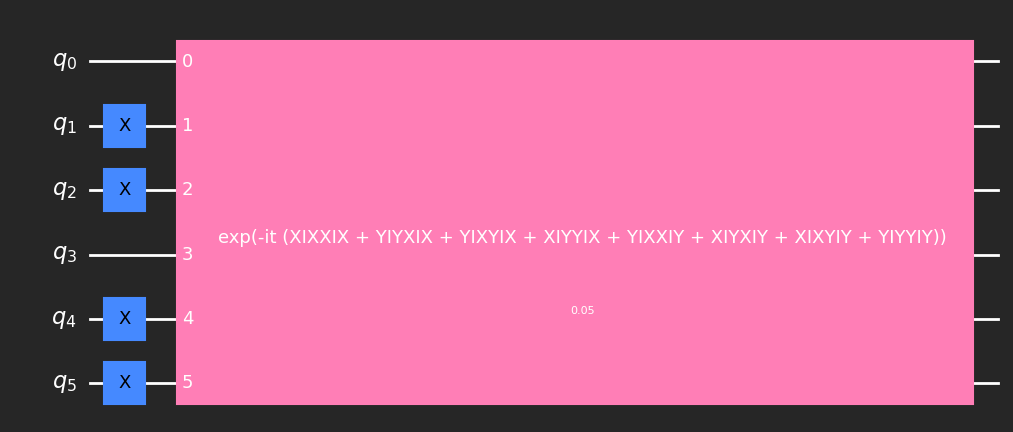

In [11]:
from qiskit import QuantumCircuit
from qiskit.circuit.library import PauliEvolutionGate
import matplotlib.pyplot as plt

epsilon = 0.05

qc = QuantumCircuit(6)

# Prepare |011011>:
# q0 q1 q2 q3 q4 q5 = 0 1 1 0 1 1
qc.x([1, 2, 4, 5])

# U_epsilon = exp(-i * epsilon * H_tilde)
evolution = PauliEvolutionGate(H_tilde, time=epsilon)

qc.append(evolution, range(6))
qc.draw(output="mpl", fold=-1, style="iqp-dark")

where the evolution accounts for $U_\varepsilon = e^{-i\varepsilon \widetilde{H}}$ (as discussed in Section 5). Due to Qiskit's little-endian qubit convention, bitstrings are ordered from highest to lowest index ($q_5 q_4 q_3 q_2 q_1 q_0$), requiring gate operations and Pauli strings to be specified in reverse order.

In [13]:
# Statevector check of the reference Qiskit evolution
state_qiskit = Statevector.from_instruction(qc)

print("P(|011011>) =", abs(state_qiskit.data[idx_00])**2)
print("P(|110110>) =", abs(state_qiskit.data[idx_22])**2)
print("Statevector fidelity against exact matrix evolution =",
      abs(np.vdot(state_qiskit.data, exact_state(epsilon)))**2)

P(|011011>) = 0.9900332889206209
P(|110110>) = 0.009966711079379187
Statevector fidelity against exact matrix evolution = 1.0


### 8.1 Explicit decomposition into the eight Pauli evolutions

Since the eight Pauli terms commute,
$$
    U_\varepsilon = \prod_{k=1}^8 \exp (-i\varepsilon c_k P_k),
$$
where $c_k = \pm 1/4$ and $P_k$ are the eight four-qubit Pauli strings. For example, the first term is
$$
    -\frac 14 X_0 X_2 X_3 X_5,
$$
so its evolution is
$$
    U_\varepsilon^{(1)} = \exp (+i \frac{\varepsilon}{4} X_0 X_2 X_3 X_5).
$$

### 8.2 Sabín's IBM-compatible decomposition

Introducing the general idea:
$$
    H = U^\dagger H_0 U \longrightarrow e^{iH\varepsilon} = U^\dagger e^{iH\varepsilon} U
$$
For the representative $XXXX$ term, Sabín uses a sequence of two-qubit $ZX$ rotations to transform the four-qubit Pauli operator into a single-qubit $Z$ rotation. The resulting circuit can then be expressed using IBM gates such as CNOT, $S$, $S^\dagger$, $R_X$, and $U_1$.

The corresponding representative implementation should then be given explicitly in Qiskit.

Sabín IBM-compatible decomposition:


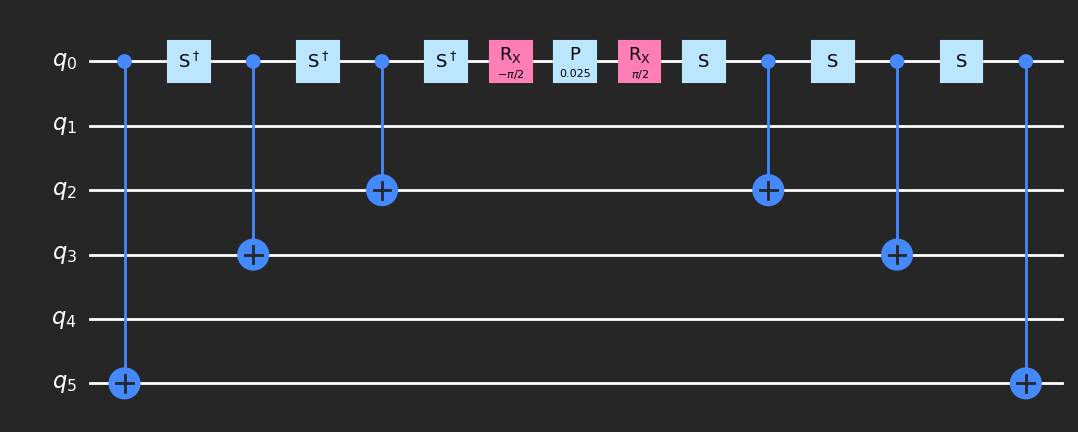

In [14]:
# Implements the decomposition of
#   U_epsilon^(1) = exp(+i * epsilon/4 * X0 X2 X3 X5)
# following Sabín, Eq. (30), up to a global phase.

import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator, SparsePauliOp, process_fidelity
from qiskit.circuit.library import PauliEvolutionGate


def sabin_xxxx_term(epsilon):
    """
    Sabín's IBM-compatible decomposition of exp(+i * epsilon/4 * X0 X2 X3 X5)
    for the six-qubit encoding used in this notebook (Eq. (30)).

    Structure (operator order, right to left = circuit order):
        CNOT(0-5) S CNOT(0-3) S CNOT(0-2) S
            RX(+pi/2) U1(eps/2) RX(-pi/2)
        Sdg CNOT(0-2) Sdg CNOT(0-3) Sdg CNOT(0-5)

    The S/Sdg gates commute with the CNOT controls, so the circuit is
        C * Sdg * [RX(pi/2) P(eps/2) RX(-pi/2)] * S * C,
    with C = CNOT(0-2) CNOT(0-3) CNOT(0-5).
        RX(pi/2) RZ(eps/2) RX(-pi/2) = exp(+i eps Y/4)
        Sdg Y S                     = X
        C X0 C                      = X0 X2 X3 X5
    giving exp(+i eps/4 X0 X2 X3 X5) up to the global phase exp(i eps/4)
    from P = exp(i eps/4) RZ.

    NOTE: the two RX gates must have opposite signs. Using RX(+pi/2)
    twice leaves an extra Pauli X, giving a circuit orthogonal to the
    target (process fidelity 0).

    Returns
    -------
    QuantumCircuit
        Six-qubit circuit implementing the decomposition.
    """
    qc = QuantumCircuit(6)

    # Right-hand part of Eq. (30)
    qc.cx(0, 5)
    qc.sdg(0)
    qc.cx(0, 3)
    qc.sdg(0)
    qc.cx(0, 2)
    qc.sdg(0)

    # Basis change Z -> Y, phase rotation, basis change back
    qc.rx(-np.pi / 2, 0)
    qc.p(epsilon / 2, 0)  # Sabín's U1(epsilon/2) == Qiskit P()
    qc.rx(np.pi / 2, 0)

    # Left-hand part of Eq. (30)
    qc.s(0)
    qc.cx(0, 2)
    qc.s(0)
    qc.cx(0, 3)
    qc.s(0)
    qc.cx(0, 5)

    return qc


# Build and display the circuit
qc_sabin = sabin_xxxx_term(epsilon)
print("Sabín IBM-compatible decomposition:")
qc_sabin.draw(output="mpl", fold=-1, style="iqp-dark")

In [15]:
# ---------------------------------------------------------------
# Verification against exp(+i * epsilon/4 * X0 X2 X3 X5)
# ---------------------------------------------------------------
# Single Pauli term, in the notebook's mathematical qubit ordering
H_xxxx = SparsePauliOp.from_list([
    (qiskit_pauli_from_math({0: "X", 2: "X", 3: "X", 5: "X"}), 1 / 4)
])

# PauliEvolutionGate implements exp(-i H t)  ->  time = -epsilon
U_reference = Operator(PauliEvolutionGate(H_xxxx, time=-epsilon))
U_sabin = Operator(qc_sabin)

print("\nEquivalent up to global phase:", U_reference.equiv(U_sabin))
print("Process fidelity:", process_fidelity(U_sabin, U_reference))

# Recover and report the global phase
k = np.argmax(np.abs(U_reference.data.ravel()))
phase = U_sabin.data.ravel()[k] / U_reference.data.ravel()[k]
print("Global phase:", np.round(phase, 8),
      " (expected exp(i*eps/4) =", np.round(np.exp(1j * epsilon / 4), 8), ")")
print("Exact match after removing phase:",
      np.allclose(U_sabin.data / phase, U_reference.data))

# Cross-check against the corresponding term of H_tilde itself:
# the XXXX term in H_tilde has coefficient -1/4, so
# exp(-i * eps * (-1/4) XXXX) = exp(+i eps/4 XXXX)
H_term_from_Htilde = SparsePauliOp.from_list([
    (qiskit_pauli_from_math({0: "X", 2: "X", 3: "X", 5: "X"}), -1 / 4)
])
U_from_Htilde = Operator(PauliEvolutionGate(H_term_from_Htilde, time=epsilon))
print("Matches the -1/4 XXXX term of H_tilde:", U_from_Htilde.equiv(U_sabin))


Equivalent up to global phase: True
Process fidelity: 0.9999999999999998
Global phase: (0.99992188+0.01249967j)  (expected exp(i*eps/4) = (0.99992188+0.01249967j) )
Exact match after removing phase: True
Matches the -1/4 XXXX term of H_tilde: True


### 8.3 Why we keep both implementations

This distinction is important:

PauliEvolutionGate → high-level/reference implementation
explicit Sabín decomposition → gate-level IBM/Qiskit implementation

We should then compare their resulting unitaries numerically. That gives us a useful validation:
$$
    U_{\varepsilon}^{\rm high-level} \approx U_{\varepsilon}^{\rm Sabín}. 
$$
Only after that should we move to transpilation and the VQE section.

### 8.4 (Optional) IBM Backend transpilation

The next cell is intentionally optional. It requires an IBM Quantum account and a backend selected by the user. It is preferable to target the actual backend rather than hard-code an old device name.

In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

service = QiskitRuntimeService()
backend = service.backend("YOUR_BACKEND_NAME")
pm = generate_preset_pass_manager(optimization_level=3, backend=backend,)
qc_ibm = pm.run(qc)

print(qc_ibm.count_ops())
print("Depth:", qc_ibm.depth())

## 9. Exact dynamics versus the perturbative state

There are two states that should no longer be conflated:

**A. Exact real-time state generated by the simulated unitary**
$$
    |\psi(\varepsilon)\rangle \simeq |00\rangle+2i\varepsilon|22\rangle.
$$
**Variational Quantum Eigensolver (VQE) target**

VQE minimizes the energy of $\widetilde H$. Because the six-qubit Hamiltonian has a four-fold degenerate ground eigenspace, VQE should be judged primarily by its energy and by its projection into the physical code space, rather than by overlap with one arbitrarily chosen numerical eigenvector.

These are different tasks:
$$ 
    \boxed{ U_\varepsilon:\text{ entanglement generation} } 
$$ 
$$
    \boxed{ \text{VQE}:\text{ ground-state energy/state preparation} } 
$$
The next notebook stage can therefore start from this validated $H_{6q}$ and address VQE separately.

## 10. Validation checklist

Before moving to VQE, the notebook should pass all of these checks:

* ✔ Correct Sabín six-qubit encoding.
* ✔ Correct eight-term Pauli Hamiltonian.
* ✔ $H^\dagger=H$.
* ✔ $H|00\rangle=-2|22\rangle$.
* ✔ $H|22\rangle=-2|00\rangle$.
* ✔ Full 64-dimensional ground energy $E_0=-2$.
* ✔ Four-fold full-space ground-state degeneracy.
* ✔ $(|00\rangle+|22\rangle)/\sqrt2$ lies in the ground eigenspace.
* ✔ Nine-state bosonic code is orthonormal.
* ✔ $V^\dagger H_{6q}V=H_{\rm boson}$.
* ✔ Exact $U_\varepsilon$ evolution remains in the $|00\rangle,|22\rangle$ sector.
* ✔ Concurrence is computed independently of the witness.
* ✔ The logical witness is explicitly distinguished from Bose et al.'s original witness.
* ✔ IBM/Qiskit evolution uses the full validated Hamiltonian.

Next stage: VQE, with explicit treatment of the four-fold ground-state degeneracy and physical-code-space constraint.

## 11. Trotterization: completing the eight-term product formula

Section 8.2 built an explicit CNOT-ladder circuit for exactly one of the eight commuting Pauli terms in $\widetilde H$ (the $X_0X_2X_3X_5$ term, following Sabín's Eq. (30)), and asserted the other seven "by symmetry". This section closes that gap using an actual quantum-simulation tool -- a general Trotter/product-formula circuit synthesizer -- rather than one bespoke gate identity, and cross-checks the result against Qiskit's own `LieTrotter`/`SuzukiTrotter` synthesis.

Since all eight terms of $\widetilde H$ commute (every term has an even number of $Ys$, so any pair differs at an even number of sites → all eight commute), $U_\varepsilon$ has **zero** Trotter splitting error for any number of repetitions -- a single product step is exact. That special structure is itself worth demonstrating explicitly here, because it will *not* hold once the notebook series moves past this truncated, exactly-solvable Hamiltonian (e.g. if oscillator self-energy terms or additional truncation levels are ever reintroduced).

### 11.1 A general CNOT-staircase Pauli exponential

For a Pauli string $P=P_{q_1}\otimes\cdots\otimes P_{q_n}$ with each $P_{q_i}\in\{X,Y\}$, $\exp(-i\theta P)$ is built the standard way:

1. Rotate every qubit into the $Z$ frame: $H$ for an $X$ factor, $S^\dagger H$ for a $Y$ factor.
2. Chain CNOTs along the qubits to accumulate the total parity onto the last qubit.
3. Apply $R_Z(2\theta)$ on that accumulator qubit.
4. Undo the CNOT chain and the basis rotations.

Sec. 8.2 applied the fan-out identity only to the $XXXX$ term; here we use a uniform construction that covers all eight. It is validated below term-by-term against `PauliEvolutionGate`, exactly the same way Sec. 8.3 validated the single hand-derived term.

In [16]:
def pauli_term_circuit(pauli_dict, angle, qubit_order=(0, 2, 3, 5), n_qubits=6, barriers=False):
    """
    Circuit implementing exp(-i * angle * P), where
        P = kron_{q in pauli_dict} pauli_dict[q],  pauli_dict[q] in {'X','Y'},
    matching the PauliEvolutionGate(op, time=angle) convention exp(-i*angle*op).

    Structure: rotate every qubit in the term into the Z frame (H for X,
    Sdg;H for Y), chain CNOTs along `qubit_order` to accumulate the parity
    onto the last qubit in that order, apply RZ(2*angle) there, then undo
    the ladder and the basis rotations.
    (visualization only; barriers prevent cross-term gate cancellation).
    """
    qubits = [q for q in qubit_order if q in pauli_dict]
    accumulator = qubits[-1]
    qc = QuantumCircuit(n_qubits)

    def bar(label):
        if barriers:
            qc.barrier(qubits, label=label)

    for q in qubits:
        if pauli_dict[q] == "Y":
            qc.sdg(q)
            qc.h(q)
        elif pauli_dict[q] == "X":
            qc.h(q)
        else:
            raise ValueError("Only X/Y supported for this Hamiltonian family.")
    bar("basis")    

    for a, b in zip(qubits[:-1], qubits[1:]):
        qc.cx(a, b)
    bar("parity")

    qc.rz(2 * angle, accumulator)
    bar("RZ")

    for a, b in reversed(list(zip(qubits[:-1], qubits[1:]))):
        qc.cx(a, b)
    bar("unparity")
    
    for q in qubits:
        if pauli_dict[q] == "Y":
            qc.h(q)
            qc.s(q)
        elif pauli_dict[q] == "X":
            qc.h(q)

    return qc

def build_full(terms, epsilon, barriers=False, term_labels=False):
    """
    Eight-term product circuit. Optional barrier after every term.
    """
    qc = QuantumCircuit(6)
    for k, (pdict, coeff) in enumerate(terms, start=1):
        qc.compose(pauli_term_circuit(pdict, epsilon * coeff, barriers=barriers), inplace=True)
        if term_labels:
            qc.barrier(label=f"T{k}:{qiskit_pauli_from_math(pdict)}")
    return qc


def reference_term_gate(pauli_dict, coeff, epsilon, n_qubits=6):
    label = qiskit_pauli_from_math(pauli_dict, n_qubits)
    op = SparsePauliOp.from_list([(label, coeff)])
    return PauliEvolutionGate(op, time=epsilon)

### 11.2 Per-term validation against `PauliEvolutionGate`

In [17]:
section("Per-term validation against PauliEvolutionGate")

full_hand = QuantumCircuit(6)
for k, (pdict, coeff) in enumerate(terms, start=1):
    angle = epsilon * coeff
    term_qc = pauli_term_circuit(pdict, angle)

    U_hand = Operator(term_qc)
    U_ref = Operator(reference_term_gate(pdict, coeff, epsilon))
    fid = process_fidelity(U_hand, U_ref)
    label = qiskit_pauli_from_math(pdict)
    print(f"Term {k}: {label:8s}  coeff={coeff:+.2f}  "
          f"process_fidelity={fid:.10f}  equiv_up_to_phase={U_hand.equiv(U_ref)}")

    full_hand.compose(term_qc, inplace=True)


Per-term validation against PauliEvolutionGate
Term 1: XIXXIX    coeff=-0.25  process_fidelity=1.0000000000  equiv_up_to_phase=True
Term 2: YIYXIX    coeff=-0.25  process_fidelity=1.0000000000  equiv_up_to_phase=True
Term 3: YIXYIX    coeff=+0.25  process_fidelity=1.0000000000  equiv_up_to_phase=True
Term 4: XIYYIX    coeff=-0.25  process_fidelity=1.0000000000  equiv_up_to_phase=True
Term 5: YIXXIY    coeff=-0.25  process_fidelity=1.0000000000  equiv_up_to_phase=True
Term 6: XIYXIY    coeff=+0.25  process_fidelity=1.0000000000  equiv_up_to_phase=True
Term 7: XIXYIY    coeff=-0.25  process_fidelity=1.0000000000  equiv_up_to_phase=True
Term 8: YIYYIY    coeff=-0.25  process_fidelity=1.0000000000  equiv_up_to_phase=True


### 11.3 Full eight-term circuit vs the reference evolution and exact $\exp(-i\varepsilon\widetilde H)$

Same three-way validation pattern as Secs. 8.3/8.4: operator-level agreement with `PauliEvolutionGate(H_tilde, time=epsilon)`, and  tatevector-level agreement with `exact_state(epsilon)`.

In [18]:
U_full_hand = Operator(full_hand)
U_full_ref = Operator(PauliEvolutionGate(H_tilde, time=epsilon))
print("Process fidelity (operator level):", process_fidelity(U_full_hand, U_full_ref))
print("Equivalent up to global phase     :", U_full_hand.equiv(U_full_ref))

full_hand_with_prep = QuantumCircuit(6)
full_hand_with_prep.x([1, 2, 4, 5])
full_hand_with_prep.compose(full_hand, inplace=True)

psi_hand = Statevector.from_instruction(full_hand_with_prep).data
psi_epsilon_exact = exact_state(epsilon)
sv_fidelity = abs(np.vdot(psi_hand, psi_epsilon_exact)) ** 2
print("Statevector fidelity (vs exact matrix evolution):", sv_fidelity)

Process fidelity (operator level): 0.9999999999999898
Equivalent up to global phase     : True
Statevector fidelity (vs exact matrix evolution): 0.9999999999999896


### 11.4 Gate-count comparison: hand-built vs Qiskit's automatic Trotter synthesis

Because the eight terms commute, increasing `reps` in `LieTrotter`/`SuzukiTrotter` cannot improve fidelity beyond the single-step result -- it can only add gates. The sweep below is included specifically to demonstrate that this exactness holds under Qiskit's own general product-formula machinery too (not just the hand-derived route above), and to get real CNOT-count/depth numbers, after transpiling everything to a common `{cx, rz, sx, x}` basis, before the optional IBM-backend transpile in Sec. 8.4 is asked to do anything meaningful with the full Hamiltonian rather than one term of it.

In [19]:
from qiskit import transpile
from qiskit.synthesis import LieTrotter, SuzukiTrotter

basis_gates = ["cx", "rz", "sx", "x"]


def stats_and_fidelity(evolution_circuit, label):
    full = QuantumCircuit(6)
    full.x([1, 2, 4, 5])
    full.compose(evolution_circuit, inplace=True)
    psi = Statevector.from_instruction(full).data
    fid = abs(np.vdot(psi, psi_epsilon_exact)) ** 2
    t = transpile(full, basis_gates=basis_gates, optimization_level=1)
    ops = dict(t.count_ops())
    print(f"{label:32s}  fidelity={fid:.12f}  "
          f"cx={ops.get('cx', 0):3d}  depth={t.depth():3d}  ops={ops}")
    return fid, ops.get("cx", 0), t.depth()


stats_and_fidelity(full_hand, "Hand-built (staircase)")

for reps in (1, 2, 4):
    gate = PauliEvolutionGate(H_tilde, time=epsilon, synthesis=LieTrotter(reps=reps))
    qc = QuantumCircuit(6)
    qc.append(gate, range(6))
    stats_and_fidelity(qc.decompose(reps=2), f"LieTrotter reps={reps} (chain)")

for reps in (1, 2):
    gate = PauliEvolutionGate(H_tilde, time=epsilon, synthesis=LieTrotter(reps=reps, cx_structure="fountain"))
    qc = QuantumCircuit(6)
    qc.append(gate, range(6))
    stats_and_fidelity(qc.decompose(reps=2), f"LieTrotter reps={reps} (fountain)")

for reps in (1, 2):
    gate = PauliEvolutionGate(H_tilde, time=epsilon, synthesis=SuzukiTrotter(order=2, reps=reps))
    qc = QuantumCircuit(6)
    qc.append(gate, range(6))
    stats_and_fidelity(qc.decompose(reps=2), f"SuzukiTrotter(2) reps={reps}")

Hand-built (staircase)            fidelity=1.000000000000  cx= 40  depth= 75  ops={'rz': 44, 'cx': 40, 'sx': 24, 'x': 2}
LieTrotter reps=1 (chain)         fidelity=1.000000000000  cx= 48  depth= 81  ops={'rz': 50, 'cx': 48, 'sx': 24, 'x': 2}
LieTrotter reps=2 (chain)         fidelity=1.000000000000  cx= 96  depth=158  ops={'cx': 96, 'rz': 88, 'sx': 44, 'x': 2}
LieTrotter reps=4 (chain)         fidelity=1.000000000000  cx=192  depth=312  ops={'cx': 192, 'rz': 164, 'sx': 84, 'x': 2}
LieTrotter reps=1 (fountain)      fidelity=1.000000000000  cx= 40  depth= 75  ops={'rz': 50, 'cx': 40, 'sx': 24, 'x': 2}
LieTrotter reps=2 (fountain)      fidelity=1.000000000000  cx= 80  depth=146  ops={'rz': 88, 'cx': 80, 'sx': 44, 'x': 2}
SuzukiTrotter(2) reps=1           fidelity=1.000000000000  cx= 90  depth=149  ops={'cx': 90, 'rz': 79, 'sx': 40, 'x': 2}
SuzukiTrotter(2) reps=2           fidelity=1.000000000000  cx=174  depth=285  ops={'cx': 174, 'rz': 141, 'sx': 72, 'x': 2}


Single term (XXYY), step barriers:


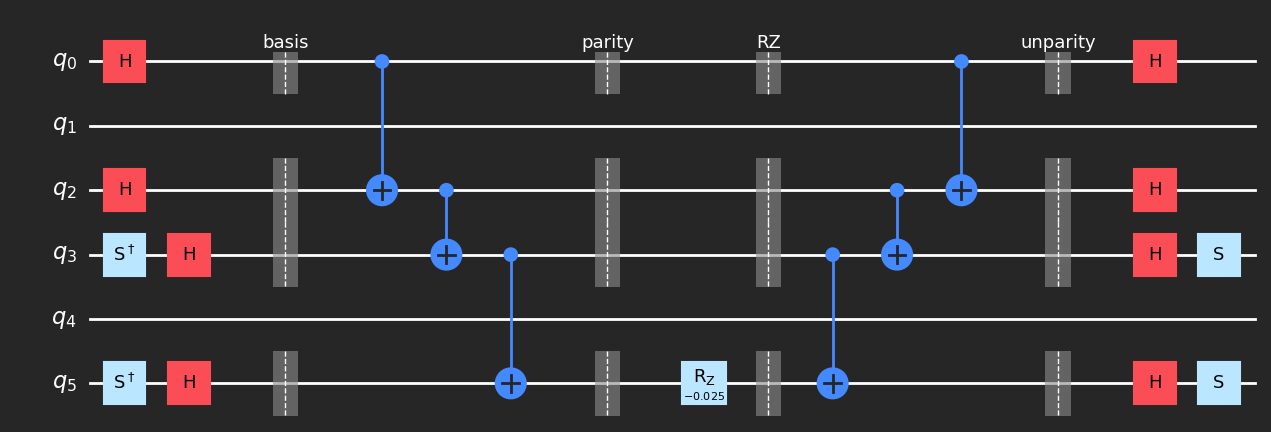

In [20]:
# --- Visualization -------------------------------------------------------
# One term with Y factors, all four steps separated
print("Single term (XXYY), step barriers:")
pauli_term_circuit(terms[1][0], epsilon * terms[1][1],
                         barriers=True).draw("mpl", fold=-1, style="iqp-dark")


Full product formula, term barriers:


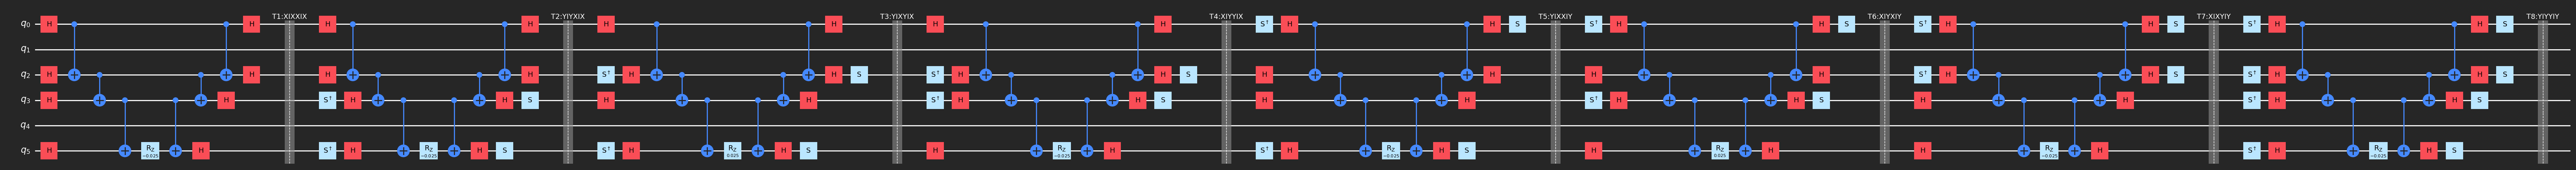

In [21]:
# Full eight-term circuit, one barrier per term
print("\nFull product formula, term barriers:")
build_full(terms, epsilon, term_labels=True).draw("mpl", fold=-1, style="iqp-dark")

In [22]:
# --- Gate counts: barrier-free circuit only -----------------------------
full_hand = build_full(terms, epsilon)                       # used for counts
full_hand_vis = build_full(terms, epsilon, term_labels=True)  # display only

for lvl in (0, 1):
    t = transpile(full_hand, basis_gates=basis_gates, optimization_level=lvl)
    print(f"opt_level={lvl}: cx={t.count_ops().get('cx', 0)}  depth={t.depth()}")

# Demonstrate the barrier penalty explicitly
t_bar = transpile(full_hand_vis, basis_gates=basis_gates, optimization_level=1)
print(f"with term barriers, opt_level=1: cx={t_bar.count_ops().get('cx', 0)}")

opt_level=0: cx=48  depth=115
opt_level=1: cx=40  depth=75
with term barriers, opt_level=1: cx=48


Visualising circuits after transpilation with the chosen `optimization_level`:

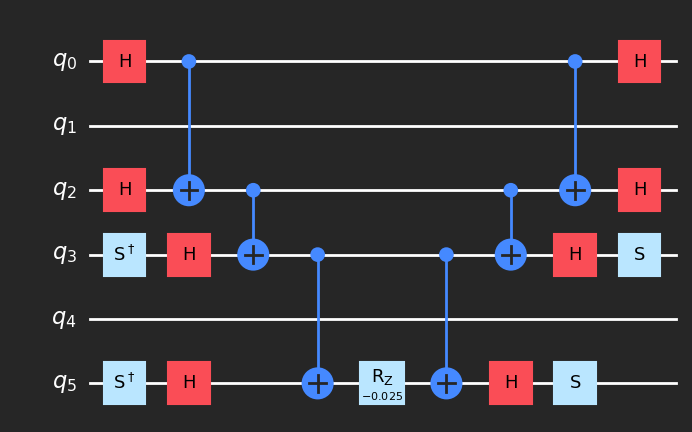

In [23]:
pauli_term_circuit(terms[1][0], epsilon * terms[1][1]).draw("mpl", fold=-1, style="iqp-dark")  # a term with Y's

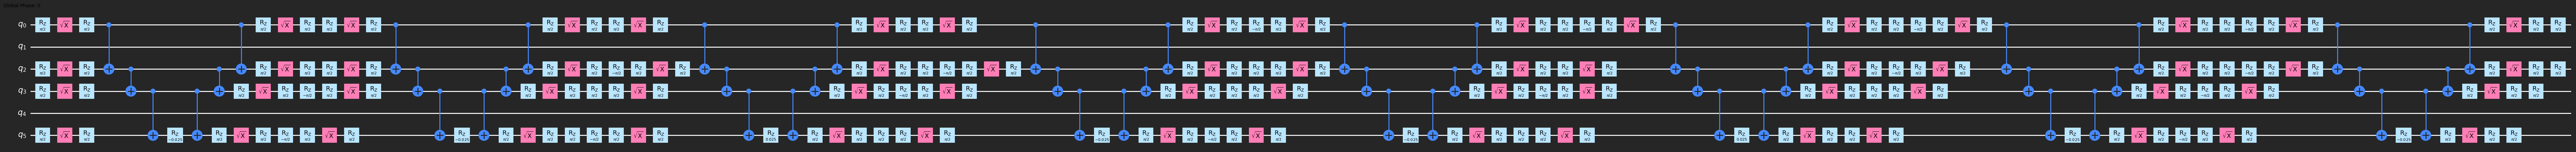

In [24]:
transpile(full_hand, basis_gates=basis_gates, optimization_level=0).draw("mpl", fold=-1, style="iqp-dark")

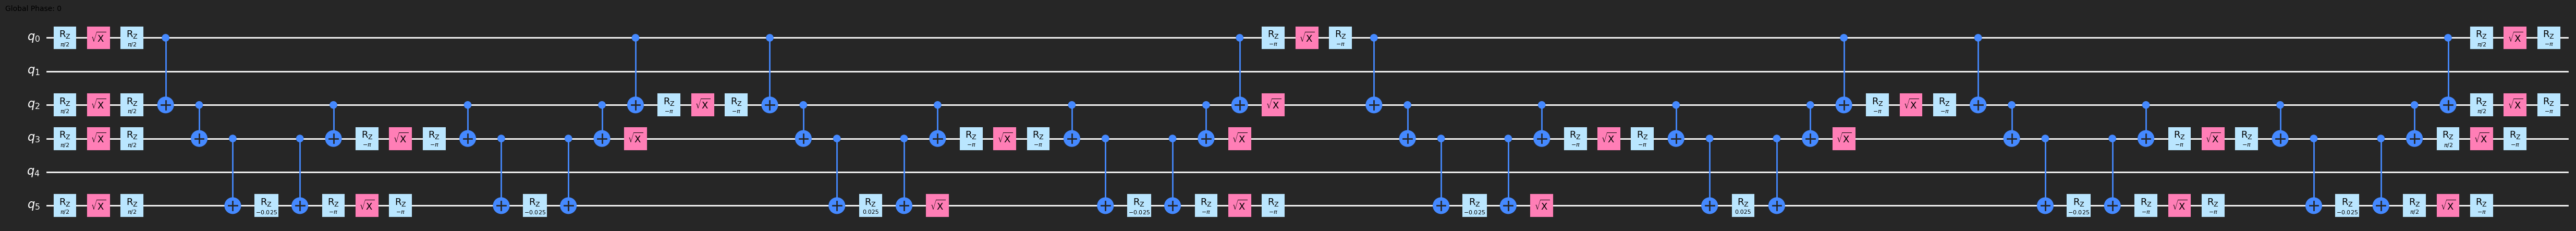

In [25]:
transpile(full_hand, basis_gates=basis_gates, optimization_level=1).draw("mpl", fold=-1, style="iqp-dark")

**Reading the table:**

| Circuit | CX count | Depth | Fidelity |
|---|---|---|---|
| Hand-built (staircase) | 40 | 75 | 1.0 |
| `LieTrotter` reps=1, chain (= Sec. 8.4 default) | 48 | 81 | 1.0 |
| `LieTrotter` reps=2, chain | 96 | 158 | 1.0 |
| `LieTrotter` reps=4, chain | 192 | 312 | 1.0 |
| `LieTrotter` reps=1, fountain | 40 | 75 | 1.0 |
| `LieTrotter` reps=2, fountain | 80 | 146 | 1.0 |
| `SuzukiTrotter`(order 2) reps=1 | 90 | 149 | 1.0 |
| `SuzukiTrotter`(order 2) reps=2 | 174 | 285 | 1.0 |

Every row hits fidelity $1.0$ to machine precision, exactly as expected for a commuting Hamiltonian -- confirming that the exactness of Sec. 8.4's single `PauliEvolutionGate` call was not a fluke of that one high-level call, but holds for every product-formula strategy Qiskit offers, and for the independently hand-derived circuit above.

The interesting number is the CX count, not the fidelity: `reps=2,4` are pure overhead here (double/quadruple the CX count for identical fidelity), and `cx_structure="fountain"` matches the hand-built staircase's 40 CNOTs, beating the default `"chain"` structure's 48. `SuzukiTrotter` costs noticeably more (90 CX at reps=1) because its order-2 formula runs the term list forward and backward -- overhead that buys nothing here since there is no splitting error to cancel, but which *will* matter once a non-commuting extension of this Hamiltonian is considered.

**Practical takeaway:** for this Hamiltonian, `PauliEvolutionGate(H_tilde, time=epsilon, synthesis=LieTrotter(reps=1, cx_structure="fountain"))` is the cheapest exact circuit available, and it makes Sec. 8.4's optional IBM-backend transpile worth actually running.

### 11.5 Looking ahead: VQE and the physical code space

Sec. 9 flagged that VQE "should be judged primarily by its energy and by its projection into the physical code space, rather than by overlap with one arbitrarily chosen numerical eigenvector," because the full six-qubit Hamiltonian has a four-fold degenerate ground eigenspace. That statement can be checked and quantified right now, using the isometry $V$ and $H_{\rm boson}$ already built in Sec. 3 -- and the answer changes how a VQE ansatz for this problem should be chosen.

In [26]:
Pi_code = V @ V.conj().T  # projector onto the 9-dimensional physical code space

Pg = eigenvectors[:, ground_indices] @ eigenvectors[:, ground_indices].conj().T
M = Pi_code @ Pg @ Pi_code
rank_in_code = int(np.sum(np.linalg.eigvalsh(M) > 1e-8))

print("Full-space ground degeneracy      :", len(ground_indices))
print("Dimension of that degeneracy lying")
print("inside the 9D physical code space  :", rank_in_code)

print()
section("Overlap of each numpy ground eigenvector with the code space:")
for idx in ground_indices:
    g = eigenvectors[:, idx]
    print(f"  eigenvector {idx}: ||Pi_code |g>||^2 = {np.real(np.vdot(g, Pi_code @ g)):.6f}")

Full-space ground degeneracy      : 4
Dimension of that degeneracy lying
inside the 9D physical code space  : 1


Overlap of each numpy ground eigenvector with the code space:
  eigenvector 0: ||Pi_code |g>||^2 = 0.000000
  eigenvector 1: ||Pi_code |g>||^2 = 0.000000
  eigenvector 2: ||Pi_code |g>||^2 = 0.000000
  eigenvector 3: ||Pi_code |g>||^2 = 1.000000


**Result:** only $1$ of the $4$ degenerate directions at $E=-2$ lies inside the $9$-dimensional physical code space; the other $3$ (in this particular `numpy.linalg.eigh` basis choice, each individually) are entirely outside it. That matches the restricted-space spectrum from Sec. 3, $\{-2,0,\dots,0,2\}$, which has $-2$ appearing with multiplicity $1$ -- the extra full-space degeneracy is a qubit-encoding artifact (three unphysical computational basis states, outside $\{011,101,110\}^{\otimes 2}$, that happen to also sit at energy $-2$ in the raw 6-qubit  Hamiltonian), not a physical feature of the truncated bosonic model.

**Consequence for VQE:** an energy-only cost function on a generic hardware-efficient ansatz over the full 64-dimensional space has three times
as much unphysical ground-energy "room" to fall into as physical room. A run that converges cleanly to $E\to-2$ is not, by itself, evidence of a correct result -- it could be sitting almost entirely in the unphysical complement of the code space. Two ways to make the next VQE notebook robust to this, in increasing order of effort:

1. **Projection-regularized cost, generic ansatz.** Keep a standard hardware-efficient ansatz (e.g. `EfficientSU2`) but optimize $\langle H\rangle+\lambda\,(1-\langle\Pi_{\rm code}\rangle)$ instead of $\langle H\rangle$ alone, and report both numbers at convergence. Reuses everything already validated in this notebook ($\Pi_{\rm code}=VV^\dagger$).
2. **Code-space-preserving ansatz.** Build the ansatz from particle-number-conserving two-qubit gates (Qiskit's `XXPlusYYGate`/Givens-rotation family) acting only within each oscillator's 3-qubit triple, initialized in a one-hot code word. Such an ansatz cannot leave the 9-dimensional code space by construction, so a plain energy-only cost function is safe -- no regularization needed, at the cost of a more structured circuit to build and validate.

Either way, this is naturally the next notebook's opening section, not part of this one: the entanglement-generation dynamics validated above ($U_\varepsilon$) and ground-state preparation (VQE) remain, as Sec. 9 already says, different tasks.

## 12 Variational Quantum Eigensolver (VQE)

So far, we have used the GIE Hamiltonian to study real-time entanglement generation. In particular, the evolution $U_\varepsilon=e^{-i\varepsilon\widetilde H}$ takes an initial physical state into an entangled state whose correlations can be studied with the logical entanglement witness.

A different question is:
>Can we use a quantum computer to find the ground state of the same GIE Hamiltonian?

This is the problem addressed by the Variational Quantum Eigensolver (VQE).

### 12.1 Basic idea

VQE uses a parameterized quantum state $U(\boldsymbol{\theta})|\psi_{\mathrm{init}}\rangle$ and minimizes its energy expectation value,
$$
    \langle\psi(\boldsymbol{\theta})|\widetilde H|\psi(\boldsymbol{\theta})\rangle .
$$
The variational principle guarantees $E(\boldsymbol{\theta})\geq E_0$, where $E_0$ is the ground-state energy. A classical optimizer therefore changes the parameters $\boldsymbol{\theta}$ while the quantum circuit evaluates the energy:
$$
    \boxed{\text{prepare state}\rightarrow\text{measure energy}\rightarrow\text{classical optimization}\rightarrow\text{update parameters}}
$$
VQE is therefore complementary to the real-time simulation used in the previous sections:
$$
    \boxed{U_\varepsilon\quad\longrightarrow\quad\text{real-time dynamics and entanglement}}
$$
whereas
$$
    \boxed{\mathrm{VQE}\quad\longrightarrow\quad\text{ground-state preparation}.}
$$
We now apply this idea directly to the six-qubit GIE Hamiltonian constructed above.

### 12.2 VQE for the GIE Hamiltonian

For the encoding used throughout this tutorial,
$$
    |00\rangle_L\leftrightarrow |011011\rangle,\qquad|22\rangle_L\leftrightarrow |110110\rangle.
$$
As verified earlier, the dimensionless Hamiltonian satisfies
$$
    \widetilde H|00\rangle_L=-2|22\rangle_L,\qquad\widetilde H|22\rangle_L=-2|00\rangle_L.
$$
Therefore, within the physical subspace, the ground state is 
$$
    \frac{|00\rangle_L+|22\rangle_L}{\sqrt2} = \frac{|011011\rangle+|110110\rangle}{\sqrt2},
$$
with $E_0=-2$. This gives us a particularly simple variational family,
$$
    \cos\theta,|011011\rangle+\sin\theta,|110110\rangle .
$$
Its energy is
$$
    \langle\psi(\theta)|\widetilde H|\psi(\theta)\rangle-4\cos\theta\sin\theta-2\sin(2\theta).
$$
The minimum occurs at $\theta=\frac{\pi}{4}$, giving $E\left(\frac{\pi}{4}\right)=-2$ and $\frac{|011011\rangle+|110110\rangle}{\sqrt2}$.

Thus, this simple VQE reproduces the physical ground state of the GIE model.

The following implementation uses the same six-qubit Hamiltonian H_tilde defined earlier. The parameterized state is represented explicitly so that the role of the variational parameter is transparent.

In [46]:
import numpy as np
from scipy.optimize import minimize
from qiskit.quantum_info import Statevector

# ------------------------------------------------------------
# GIE VQE ansatz
# |psi(theta)> = cos(theta)|011011> + sin(theta)|110110>
# ------------------------------------------------------------

def gie_vqe_state(theta):
    state = np.zeros(2**6, dtype=complex)

    # Mathematical qubit order: q0 q1 q2 q3 q4 q5
    state[int("011011"[::-1], 2)] = np.cos(theta)
    state[int("110110"[::-1], 2)] = np.sin(theta)

    return Statevector(state)


# ------------------------------------------------------------
# VQE cost function
# ------------------------------------------------------------

def vqe_cost(x):
    theta = x[0]
    psi = gie_vqe_state(theta)

    return np.real(psi.expectation_value(H_tilde))


# ------------------------------------------------------------
# Classical optimization
# ------------------------------------------------------------

result = minimize(
    vqe_cost,
    x0=[0.1],
    method="COBYLA"
)

theta_opt = result.x[0]
energy_opt = vqe_cost([theta_opt])

print(f"Optimal theta : {theta_opt:.6f}")
print(f"VQE energy    : {energy_opt:.6f}")
print(f"Exact energy  : {-2.0:.6f}")

Optimal theta : 0.785400
VQE energy    : -2.000000
Exact energy  : -2.000000


The expected result is approximately

    Optimal theta : 0.785398
    VQE energy    : -2.000000
    Exact energy  : -2.000000

corresponding to $\theta_{\mathrm{opt}}\approx\frac{\pi}{4}$. The resulting state is therefore $|\psi(\theta_{\mathrm{opt}})\rangle\approx\frac{|011011\rangle+|110110\rangle}{\sqrt2}$.

### 12.3 Relation to the GIE experiment

It is important to distinguish this VQE state from the state used in the GIE entanglement experiment. The real-time experiment starts from $|00\rangle_L$ and evolves it according to $e^{-i\varepsilon\widetilde H}|00\rangle_L$. For example,
$$
    \cos(2\varepsilon)|00\rangle_L + i\sin(2\varepsilon)|22\rangle_L.
$$
The relative phase generated by this evolution is what produces the dynamical correlations studied earlier.

VQE instead searches for a lowest-energy stationary state, $\frac{|00\rangle_L+|22\rangle_L}{\sqrt2}$. Therefore, VQE is not another way of generating the time-dependent GIE signal. It is a complementary method for finding the ground state of the same Hamiltonian.

Finally, because the six-qubit register contains a $64$-dimensional Hilbert space while the truncated bosonic model contains only $3\times3=9$ physical states, a general VQE ansatz must be treated carefully. A generic variational circuit can leave the physical code space. The simple ansatz used above avoids this problem by construction: it remains entirely within the physical subspace spanned by
$$
    |011011\rangle \quad\text{and}\quad |110110\rangle.
$$
For this tutorial, this simple example is sufficient to demonstrate how VQE can be applied to the same GIE Hamiltonian without introducing a separate VQE framework.